# Блок 8. Глубокое обучение и архитектура нейросетей
## Занятие 2. Многослойная нейронная сеть: Forward Pass

## Цель занятия

На занятии 1 мы разобрали один искусственный нейрон.

Сегодня делаем следующий шаг:

```text
несколько нейронов объединяются в слой,
а несколько слоёв образуют нейронную сеть
```

Главная цель занятия — понять, как данные проходят через сеть от входа к выходу.

Этот процесс называется:

```text
Forward Pass
```

---

## Что такое слой нейронной сети

Один нейрон считает:

```text
z = x1*w1 + x2*w2 + ... + xn*wn + b
```

Но если нейронов несколько, то у каждого нейрона свои веса.

Поэтому слой можно записать через матрицы:

```text
Z = X @ W + b
```

Где:

| Обозначение | Смысл |
|---|---|
| X | таблица входных данных |
| W | матрица весов |
| b | вектор смещений |
| Z | выход слоя до активации |
| A | выход слоя после активации |

---

## Что такое многослойная сеть

Простая нейросеть может состоять из трёх частей:

```text
Входные признаки → Скрытый слой → Выходной слой
```

Например:

```text
3 входных признака → 4 скрытых нейрона → 1 выходной нейрон
```

---

## Почему нужен скрытый слой

Один нейрон умеет строить только простую границу решения.

Скрытый слой позволяет сети создавать более сложные признаки.

Например, сеть может не просто смотреть на часы подготовки студента, а находить комбинации:

- хорошо готовился + качественное ДЗ;
- сложная тема + слабая подготовка;
- высокая мотивация + средняя сложность.

---

## Что такое Forward Pass

Forward Pass — это прямой проход данных через сеть:

```text
X → Linear Layer → Activation → Linear Layer → Output
```

В этом занятии мы ещё не обучаем сеть.  
Мы задаём веса вручную и смотрим, как сеть делает прогноз.

Обучение, ошибка, градиентный спуск и backpropagation будут дальше.

---

## Связь с дипломом

Forward Pass нужен во всех проектах глубокого обучения:

- классификация изображений;
- распознавание текста;
- анализ временных рядов;
- чат-боты;
- RAG-системы;
- LLM-интерфейсы;
- компьютерное зрение.

---

## GitHub Workflow занятия

```bash
git checkout main
git pull origin main
git checkout -b feature/block8-lesson02-mlp-forward

git add .
git commit -m "feat: add block8 lesson02 mlp forward pass"
git push -u origin feature/block8-lesson02-mlp-forward
```

---

## Задача урока для переноса в VS Code

Создать файл:

```text
src/mlp_forward.py
```

И реализовать в нём функции:

```python
dense_layer(X, W, b)
relu(z)
sigmoid(z)
mlp_predict(X, W1, b1, W2, b2)
count_parameters(input_size, hidden_size, output_size)
```

Затем проверить функции через `assert`.


Сначала изучите SOLVED-ноутбук вместе с преподавателем. Затем выполните TODO-версию самостоятельно.

## Ячейка 1. TODO: импорт библиотек

### Алгоритм

1. Импортируйте `numpy`.
2. Импортируйте `matplotlib.pyplot`.
3. Настройте `np.random.seed(42)`.
4. Проверьте импорты через `assert`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

print("Библиотеки подключены")
print("NumPy version:", np.__version__)

assert np is not None
assert plt is not None

Библиотеки подключены
NumPy version: 2.5.4


## Ячейка 2. TODO: мини-датасет студентов

### Алгоритм

1. Создайте матрицу X из 6 студентов и 3 признаков.
2. Создайте y с правильными ответами.
3. Создайте список feature_names.
4. Проверьте формы X и y.

In [5]:
# TODO: создайте X = np.array([...])
X = np.array([
    [0.20, 0.30, 0.30],  # 0. Ленивый       — готовится мало, ДЗ слабое, берёт лёгкое
    [0.85, 0.80, 0.90],  # 1. Амбициозный   — пашет, хорошее ДЗ, берёт сложное
    [0.95, 0.95, 0.85],  # 2. Ботан         — максимум усилий, идеальное ДЗ, сложные темы
    [0.15, 0.20, 0.50],  # 3. Распиздяй     — почти не готовится, ДЗ на отвали, тема случайная
    [0.05, 0.10, 0.40],  # 4. Прогульщик    — не готовится, ДЗ нет, тема случайная
    [0.70, 0.40, 0.20],  # 5. Медленный     — часов много, но ДЗ слабое, тема лёгкая
    [0.90, 0.95, 0.80],  # 6. Перфекционист — много часов, идеальное ДЗ, сложная тема
    [0.50, 0.50, 0.50],  # 7. Середняк      — всего понемногу, «ни рыба ни мясо»
    [0.30, 0.40, 0.60],  # 8. Выгоревший    — раньше старался, сейчас на минимуме
    [0.10, 0.30, 0.20],  # 9. Халявщик      — минимум усилий, ДЗ списано
    [0.30, 0.85, 0.90],  # 10. Гений-лентяй — почти не готовится, но всё схватывает
    [0.90, 0.80, 0.30],  # 11. Зубрила      — зубрит много, ДЗ хорошее, но боится сложного
    [0.60, 0.70, 0.85],  # 12. Креативный   — готовится средне, ДЗ нестандартное, любит сложное
    [0.20, 0.20, 0.50],  # 13. Спящий       — на парах спит, ДЗ нет, тема случайная
    [0.80, 0.85, 0.70],  # 14. Старатель    — стабильно пашет, хорошее ДЗ, средняя тема
], dtype=float)
# TODO: создайте y = np.array([...]).reshape(-1, 1)
y = np.array([0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1]).reshape(-1, 1)
# TODO: создайте feature_names
feature_names = [
    "student_hours",
    "homework_quality",
    "topic_difficulty",
]
# TODO: выведите X, y и их формы
print("X:")
print(X)
print("y:")
print(y.ravel())
print("Форма X:", X.shape)
print("Форма y:", y.shape)
# TODO: assert X.shape == (6, 3)
assert X.shape == (15, 3)
assert y.shape == (15, 1)
# TODO: assert y.shape == (6, 1)

assert X.min() >= 0 and X.max() <= 1

X:
[[0.2  0.3  0.3 ]
 [0.85 0.8  0.9 ]
 [0.95 0.95 0.85]
 [0.15 0.2  0.5 ]
 [0.05 0.1  0.4 ]
 [0.7  0.4  0.2 ]
 [0.9  0.95 0.8 ]
 [0.5  0.5  0.5 ]
 [0.3  0.4  0.6 ]
 [0.1  0.3  0.2 ]
 [0.3  0.85 0.9 ]
 [0.9  0.8  0.3 ]
 [0.6  0.7  0.85]
 [0.2  0.2  0.5 ]
 [0.8  0.85 0.7 ]]
y:
[0 1 1 0 0 0 1 1 0 0 1 1 1 0 1]
Форма X: (15, 3)
Форма y: (15, 1)


## Ячейка 3. TODO: веса скрытого слоя

### Алгоритм

1. Создайте input_size = 3.
2. Создайте hidden_size = 4.
3. Создайте W1 формы (3, 4).
4. Создайте b1 формы (4,).
5. Проверьте размеры.

In [6]:
# TODO: создайте input_size
input_size = 3
# TODO: создайте hidden_size
hidden_size = 4
# TODO: создайте W1 = np.array([...])
W1 = np.array([
    [1.2, -0.7, 0.5, 1.0],
    [1.5, 0.8, -0.4, 0.6],
    [-1.0, 1.1, 0.9, -0.8]
])
# TODO: создайте b1 = np.array([...])
b1 = np.array([-0.5, 0.1, -0.2, 0.0])
# TODO: выведите формы W1 и b1

# TODO: assert W1.shape == (input_size, hidden_size)

# TODO: assert b1.shape == (hidden_size,)
print("W1:")
print(W1)
print("b1:", b1)
print("Форма W1:", W1.shape)
print("Форма b1:", b1.shape)

assert W1.shape == (input_size, hidden_size)
assert b1.shape == (hidden_size,)

W1:
[[ 1.2 -0.7  0.5  1. ]
 [ 1.5  0.8 -0.4  0.6]
 [-1.   1.1  0.9 -0.8]]
b1: [-0.5  0.1 -0.2  0. ]
Форма W1: (3, 4)
Форма b1: (4,)


## Ячейка 4. TODO: функция dense_layer

### Алгоритм

1. Создайте функцию `dense_layer(X, W, b)`.
2. Верните `X @ W + b`.
3. Посчитайте Z1.
4. Проверьте форму результата.

In [8]:
# TODO: создайте функцию dense_layer(X, W, b)
def dense_layer(X, W, b):
    return X @ W + b


# TODO: посчитайте Z1
Z1 = dense_layer(X, W1, b1)
# TODO: выведите Z1
print("Z1 - выход скрытого слоя до активации:")
print(np.round(Z1, 3))
print("Форма Z1:", Z1.shape)
# TODO: assert Z1.shape == (6, 4)
assert Z1.shape == (15, 4)
# TODO: проверьте первый элемент вручную
manual_first_value = X[0] @ W1[:, 0] + b1[0]
assert abs(Z1[0, 0] - manual_first_value) < 1e-9

Z1 - выход скрытого слоя до активации:
[[-0.11   0.53   0.05   0.14 ]
 [ 0.82   1.135  0.715  0.61 ]
 [ 1.215  1.13   0.66   0.84 ]
 [-0.52   0.705  0.245 -0.13 ]
 [-0.69   0.585  0.145 -0.21 ]
 [ 0.74   0.15   0.17   0.78 ]
 [ 1.205  1.11   0.59   0.83 ]
 [ 0.35   0.7    0.3    0.4  ]
 [-0.14   0.87   0.33   0.06 ]
 [-0.13   0.49  -0.09   0.12 ]
 [ 0.235  1.56   0.42   0.09 ]
 [ 1.48   0.44   0.2    1.14 ]
 [ 0.42   1.175  0.585  0.34 ]
 [-0.46   0.67   0.27  -0.08 ]
 [ 1.035  0.99   0.49   0.75 ]]
Форма Z1: (15, 4)


## Ячейка 5. TODO: ReLU в скрытом слое

### Алгоритм

1. Создайте функцию `relu(z)`.
2. Примените её к Z1.
3. Получите A1.
4. Постройте тепловую карту активаций.
5. Проверьте, что нет отрицательных значений.

A1 - выходного слоя после ReLU:
[[0.    0.53  0.05  0.14 ]
 [0.82  1.135 0.715 0.61 ]
 [1.215 1.13  0.66  0.84 ]
 [0.    0.705 0.245 0.   ]
 [0.    0.585 0.145 0.   ]
 [0.74  0.15  0.17  0.78 ]
 [1.205 1.11  0.59  0.83 ]
 [0.35  0.7   0.3   0.4  ]
 [0.    0.87  0.33  0.06 ]
 [0.    0.49  0.    0.12 ]
 [0.235 1.56  0.42  0.09 ]
 [1.48  0.44  0.2   1.14 ]
 [0.42  1.175 0.585 0.34 ]
 [0.    0.67  0.27  0.   ]
 [1.035 0.99  0.49  0.75 ]]


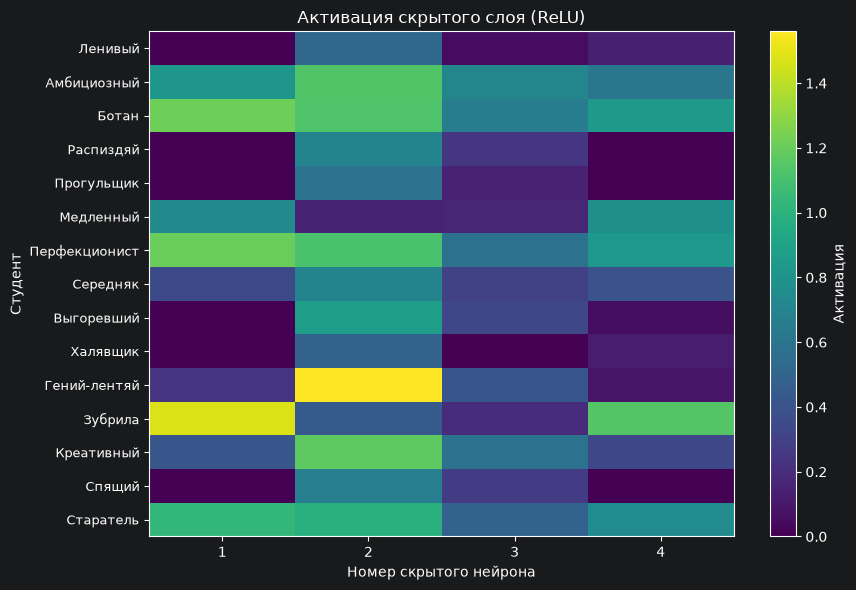

In [11]:
# TODO: создайте функцию relu(z)
def relu(z):
    return np.maximum(0, z)


A1 = relu(Z1)
# TODO: посчитайте A1
print("A1 - выходного слоя после ReLU:")
# TODO: выведите A1
print(np.round(A1, 3))

# TODO: постройте plt.imshow(A1)
import matplotlib.pyplot as plt

# Имена — ровно в том порядке, в каком студенты лежат в X (строки 0..14)
names = [
    "Ленивый",  # 0
    "Амбициозный",  # 1
    "Ботан",  # 2
    "Распиздяй",  # 3
    "Прогульщик",  # 4
    "Медленный",  # 5
    "Перфекционист",  # 6
    "Середняк",  # 7
    "Выгоревший",  # 8
    "Халявщик",  # 9
    "Гений-лентяй",  # 10
    "Зубрила",  # 11
    "Креативный",  # 12
    "Спящий",  # 13
    "Старатель",  # 14
]
assert len(names) == A1.shape[0], "Имён должно быть столько же, сколько строк в A1"

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(A1, aspect="auto", cmap="viridis")

# --- Ось X: нейроны 1–4 ---
ax.set_xticks(range(A1.shape[1]))  # позиции 0,1,2,3
ax.set_xticklabels(range(1, A1.shape[1] + 1))  # подписи 1,2,3,4
ax.set_xlabel("Номер скрытого нейрона")

# --- Ось Y: имена студентов ---
ax.set_yticks(range(A1.shape[0]))  # позиции 0..14
ax.set_yticklabels(names, fontsize=9)
ax.set_ylabel("Студент")

ax.set_title("Активация скрытого слоя (ReLU)")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Активация")

plt.tight_layout()
plt.show()
# TODO: добавьте colorbar, title, xlabel, ylabel

# TODO: assert A1.min() >= 0
assert A1.shape == Z1.shape
assert A1.min() >= 0
assert relu(-5) == 0
assert relu(3) == 3

## Ячейка 6. TODO: выходной слой и Sigmoid

### Алгоритм

1. Создайте функцию `sigmoid(z)`.
2. Создайте output_size = 1.
3. Создайте W2 формы (4, 1).
4. Создайте b2 формы (1,).
5. Посчитайте Z2 и probabilities.
6. Проверьте диапазон вероятностей.

In [12]:
# TODO: создайте функцию sigmoid(z)
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


# TODO: создайте output_size
output_size = 1
# TODO: создайте W2
W2 = np.array([
    [1.4],
    [-0.8],
    [-0.6],
    [1.2]
])
# TODO: создайте b2
b2 = np.array([-0.7])
# TODO: посчитайте Z2
Z2 = dense_layer(A1, W2, b2)
# TODO: посчитайте probabilities
probabilities = sigmoid(Z2)
# TODO: assert probabilities.shape == (6, 1)
print("Z2:")
print(np.round(Z2, 3))
print("Вероятности:")
print(np.round(probabilities, 3))
print(np.round(probabilities, 3))
# TODO: assert probabilities.min() >= 0 and probabilities.max() <= 1
assert W2.shape == (hidden_size, output_size)
assert b2.shape == (output_size,)
assert probabilities.shape == (15, 1)
assert probabilities.min() >= 0 and probabilities.max() <= 1
assert round(float(sigmoid(0)), 4) == 0.5

Z2:
[[-0.986]
 [-0.157]
 [ 0.709]
 [-1.411]
 [-1.255]
 [ 1.05 ]
 [ 0.741]
 [-0.47 ]
 [-1.522]
 [-0.948]
 [-1.763]
 [ 2.268]
 [-0.995]
 [-1.398]
 [ 0.563]]
Вероятности:
[[0.272]
 [0.461]
 [0.67 ]
 [0.196]
 [0.222]
 [0.741]
 [0.677]
 [0.385]
 [0.179]
 [0.279]
 [0.146]
 [0.906]
 [0.27 ]
 [0.198]
 [0.637]]
[[0.272]
 [0.461]
 [0.67 ]
 [0.196]
 [0.222]
 [0.741]
 [0.677]
 [0.385]
 [0.179]
 [0.279]
 [0.146]
 [0.906]
 [0.27 ]
 [0.198]
 [0.637]]


## Ячейка 7. TODO: полная функция mlp_predict

### Алгоритм

1. Создайте функцию `mlp_predict`.
2. Внутри выполните dense → ReLU → dense → Sigmoid.
3. Получите mlp_probabilities.
4. Проверьте результат.

In [22]:
# TODO: создайте функцию mlp_predict(X, W1, b1, W2, b2)
def mlp_predict(X, W1, b1, W2, b2):
    Z1 = dense_layer(X, W1, b1)
    A1 = relu(Z1)
    Z2 = dense_layer(A1, W2, b2)
    return sigmoid(Z2)


# TODO: посчитайте mlp_probabilities
mlp_probabilities = mlp_predict(X, W1, b1, W2, b2)
# TODO: выведите вероятности
print("Вероятности через mlp_predict:")
for i in sorted(zip(names, np.round(mlp_probabilities, 3).ravel())):
    print(f"{i[0]:14} - {float(i[1])}")
# TODO: assert mlp_probabilities.shape == (6, 1)

assert np.allclose(mlp_probabilities, probabilities)
assert mlp_probabilities.shape == (15, 1)

Вероятности через mlp_predict:
Амбициозный    - 0.461
Ботан          - 0.67
Выгоревший     - 0.179
Гений-лентяй   - 0.146
Зубрила        - 0.906
Креативный     - 0.27
Ленивый        - 0.272
Медленный      - 0.741
Перфекционист  - 0.677
Прогульщик     - 0.222
Распиздяй      - 0.196
Середняк       - 0.385
Спящий         - 0.198
Старатель      - 0.637
Халявщик       - 0.279


## Ячейка 8. TODO: классы, accuracy и сравнение с ответами

### Алгоритм

1. Преобразуйте вероятности в классы.
2. Сравните predictions с y.
3. Посчитайте accuracy.
4. Создайте result_table.
5. Проверьте диапазон accuracy.

In [27]:
# TODO: создайте predictions
predictions = (mlp_probabilities >= 0.5).astype(int)
# TODO: посчитайте accuracy
accuracy = np.mean(predictions == y)
# TODO: создайте result_table
result_table = np.column_stack([
    names,
    X,
    y,
    np.round(mlp_probabilities, 3),
    predictions
])
# TODO: выведите result_table и accuracy
print("Колонки: tag, study_hours, homework_quality, topic_difficulty, y_true, probability, prediction")
print(result_table)
print("Accuracy:", round(float(accuracy), 3))
# TODO: assert predictions.shape == y.shape

# TODO: assert 0 <= accuracy <= 1
assert predictions.shape == y.shape
assert 0 <= accuracy <= 1
assert set(predictions.ravel()).issubset({0, 1})

Колонки: tag, study_hours, homework_quality, topic_difficulty, y_true, probability, prediction
[['Ленивый' '0.2' '0.3' '0.3' '0' '0.272' '0']
 ['Амбициозный' '0.85' '0.8' '0.9' '1' '0.461' '0']
 ['Ботан' '0.95' '0.95' '0.85' '1' '0.67' '1']
 ['Распиздяй' '0.15' '0.2' '0.5' '0' '0.196' '0']
 ['Прогульщик' '0.05' '0.1' '0.4' '0' '0.222' '0']
 ['Медленный' '0.7' '0.4' '0.2' '0' '0.741' '1']
 ['Перфекционист' '0.9' '0.95' '0.8' '1' '0.677' '1']
 ['Середняк' '0.5' '0.5' '0.5' '1' '0.385' '0']
 ['Выгоревший' '0.3' '0.4' '0.6' '0' '0.179' '0']
 ['Халявщик' '0.1' '0.3' '0.2' '0' '0.279' '0']
 ['Гений-лентяй' '0.3' '0.85' '0.9' '1' '0.146' '0']
 ['Зубрила' '0.9' '0.8' '0.3' '1' '0.906' '1']
 ['Креативный' '0.6' '0.7' '0.85' '1' '0.27' '0']
 ['Спящий' '0.2' '0.2' '0.5' '0' '0.198' '0']
 ['Старатель' '0.8' '0.85' '0.7' '1' '0.637' '1']]
Accuracy: 0.667


## Ячейка 9. TODO: карта решений многослойной сети

### Алгоритм

1. Создайте сетку hours_grid и quality_grid.
2. Создайте H, Q через np.meshgrid.
3. Зафиксируйте сложность темы.
4. Заполните P вероятностями.
5. Постройте contourf-график.

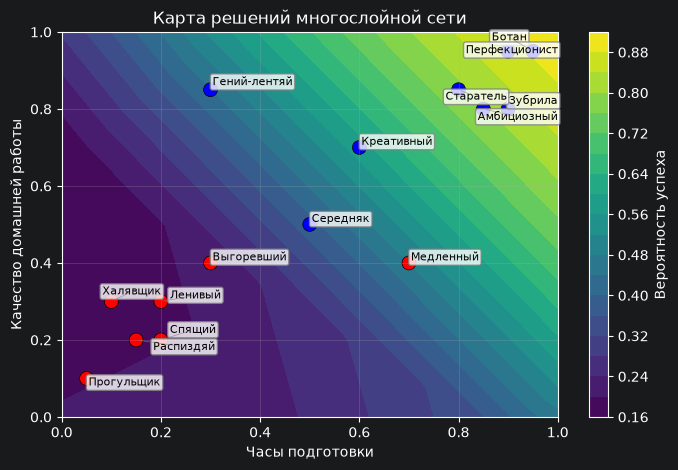

In [58]:
from matplotlib.colors import ListedColormap
from adjustText import adjust_text

hours_grid = np.linspace(0, 1, 80)
quality_grid = np.linspace(0, 1, 80)

H, Q = np.meshgrid(hours_grid, quality_grid)

fixed_difficulty = 0.5

P = np.zeros_like(H)



for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        sample = np.array([[H[i, j], Q[i, j], fixed_difficulty]])
        P[i, j] = mlp_predict(sample, W1, b1, W2, b2)[0, 0]

plt.figure(figsize=(8, 5))
contour = plt.contourf(H, Q, P, levels=20, cmap="viridis", alpha=1)
cbar = plt.colorbar(contour)
cbar.set_label("Вероятность успеха")

point_cmap = ListedColormap(["red", "blue"])
plt.scatter(
    X[:, 0], X[:, 1],
    c=y.ravel(),
    cmap=point_cmap,        # контрастная палитра
    s=100,                  # увеличиваем размер точек (было по умолчанию 20)
    edgecolors="black",     # чёрная обводка
    linewidths=0.5,         # толщина обводки
)

plt.title("Карта решений многослойной сети")
plt.xlabel("Часы подготовки")
plt.ylabel("Качество домашней работы")
plt.grid(True, alpha=0.3)
texts = []
for i, name in enumerate(names):
    t = plt.text(X[i, 0], X[i, 1], name, fontsize=8, color="black",
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.8))
    texts.append(t)
adjust_text(texts,
            arrowprops=dict(arrowstyle='-', color='gray', lw=0.5, alpha=0.7),
            expand_points=(1.5, 1.5)
            )
plt.show()


assert P.shape == H.shape
assert P.min() >= 0 and P.max() <= 1

## Ячейка 10. TODO: количество параметров и итоговый отчёт

### Алгоритм

1. Создайте функцию `count_parameters`.
2. Посчитайте params_count.
3. Посчитайте params_by_size для разных hidden_size.
4. Постройте график.
5. Создайте lesson_report.
6. Выведите GitHub-команды.

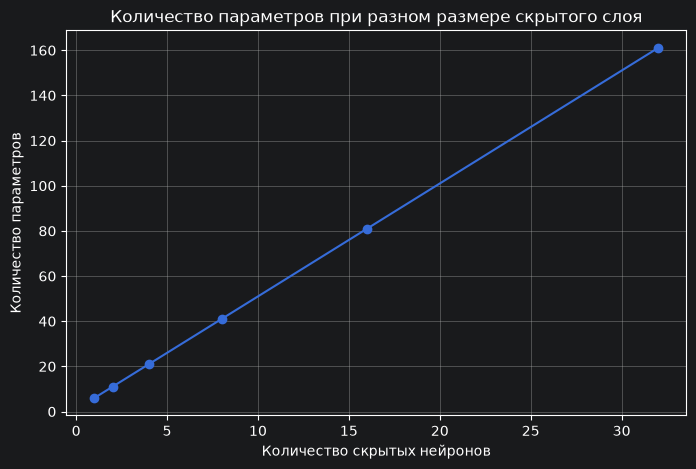

Итоговый отчёт занятия:
topic : Многослойная нейронная сеть
input_size : 3
hidden_size : 4
output_size : 1
parameters : 21
accuracy : 0.667
vscode_file : src/mlp_forward.py

GitHub:
git checkout main
git pull origin main
git checkout -b feature/block8-lesson02-mlp-forward
git add .
git commit -m "feat: add block8 lesson02 mlp forward pass"
git push -u origin feature/block8-lesson02-mlp-forward


In [59]:
def count_parameters(input_size, hidden_size, output_size):
    input_to_hidden = input_size * hidden_size
    hidden_bias = hidden_size
    hidden_to_output = hidden_size * output_size
    output_bias = output_size
    return input_to_hidden + hidden_bias + hidden_to_output + output_bias


params_count = count_parameters(
    input_size=input_size,
    hidden_size=hidden_size,
    output_size=output_size
)

hidden_sizes = np.array([1, 2, 4, 8, 16, 32])

params_by_size = np.array([
    count_parameters(input_size, size, output_size)
    for size in hidden_sizes
])

plt.figure(figsize=(8, 5))
plt.plot(hidden_sizes, params_by_size, marker="o")
plt.title("Количество параметров при разном размере скрытого слоя")
plt.xlabel("Количество скрытых нейронов")
plt.ylabel("Количество параметров")
plt.grid(True)
plt.show()

lesson_report = {
    "topic": "Многослойная нейронная сеть",
    "input_size": input_size,
    "hidden_size": hidden_size,
    "output_size": output_size,
    "parameters": int(params_count),
    "accuracy": round(float(accuracy), 3),
    "vscode_file": "src/mlp_forward.py"
}

print("Итоговый отчёт занятия:")
for key, value in lesson_report.items():
    print(key, ":", value)

print()
print("GitHub:")
print("git checkout main")
print("git pull origin main")
print("git checkout -b feature/block8-lesson02-mlp-forward")
print("git add .")
print('git commit -m "feat: add block8 lesson02 mlp forward pass"')
print("git push -u origin feature/block8-lesson02-mlp-forward")

assert params_count == 21
assert len(params_by_size) == len(hidden_sizes)
assert lesson_report["parameters"] == 21

# Итог TODO-задания

Покажите преподавателю:

- матрицу входных данных X;
- матрицу весов W1;
- функцию `dense_layer`;
- скрытый слой до и после ReLU;
- выходной слой;
- функцию `mlp_predict`;
- accuracy;
- карту решений;
- подсчёт параметров;
- GitHub-коммит;
- файл `src/mlp_forward.py` в VS Code.